# Fase II. WODPredict-AI: ejecución, contenerización y despliegue local

**Objetivo:** convertir el modelo de sobrecarga de las Actividades 5 y 6 en una **solución técnica completa y desplegable**:
artefacto del modelo, API REST con FastAPI, formulario web que consume la API, contenedor Docker y pruebas.

Este notebook se ejecuta en **VS Code** (no en Colab) porque necesita **Docker Desktop** en la misma computadora.

| Punto | Contenido | Entregable de la Fase II |
|---|---|---|
| 0 | Preparación del entorno (versiones fijas) | Archivos de configuración |
| 1 | Modelo final: entrenar y exportar el artefacto | Código fuente |
| 2 | Prueba del artefacto fuera del entrenamiento | Código fuente |
| 3 | API local sin Docker (uvicorn) | Evidencia de integración (API) |
| 4 | Construcción de la imagen Docker | Dockerfile + imagen construida |
| 5 | Ejecución del contenedor | Ejecución local comprobable |
| 6 | Integración: endpoints, request/response, frontend y cliente externo | Evidencia de integración |
| 7 | Pruebas funcionales, casos extremos y validación de entrada | Documento de validación y pruebas |
| 8 | Consistencia y latencia | Documento de validación y pruebas |
| 9 | Pruebas automatizadas con pytest | Documento de validación y pruebas |
| 10 | Detener el contenedor | — |
| 11 | Conclusiones | Documento de validación y pruebas |

**Requisitos antes de ejecutar:** Docker Desktop abierto, el ambiente de Python 3.12 con `requirements-dev.txt`
instalado y el kernel de ese ambiente seleccionado en VS Code.

## 0. Preparación del entorno

Las versiones quedan **fijas** en `requirements.txt` (las que usa la imagen de Docker) y en `requirements-dev.txt`
(las extra para entrenar, probar y ejecutar este notebook). Se imprimen para comprobar que coinciden.

In [1]:
# Punto 0. Preparación del entorno: librerías, versiones y rutas.
import sys
import json
import time
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import joblib
import fastapi
import requests
import matplotlib.pyplot as plt

# Carpeta raíz del repositorio (el notebook vive en notebooks/).
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EVIDENCIAS = RAIZ / "evidencias"            # aquí se guardan tablas y gráficas para los documentos
EVIDENCIAS.mkdir(exist_ok=True)
sys.path.append(str(RAIZ / "src"))           # para importar entrenar_modelo.py y model_loader.py

# Versiones usadas (deben coincidir con requirements.txt).
versiones = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
             "scikit-learn": sklearn.__version__, "joblib": joblib.__version__, "fastapi": fastapi.__version__}
print("Carpeta del repositorio:", RAIZ)
for libreria, version in versiones.items():
    print(f"  {libreria:13s} {version}")

# Docker: versión del cliente y del servidor (Docker Desktop debe estar abierto).
resultado = subprocess.run(["docker", "version", "--format", "Cliente {{.Client.Version}} | Servidor {{.Server.Version}}"],
                           capture_output=True, text=True)
print("\nDocker:", resultado.stdout.strip() or resultado.stderr.strip())

Carpeta del repositorio: <ruta-local>\WODPredict-AI-FaseII
  python        3.12.16
  numpy         2.0.2
  pandas        2.2.2
  scikit-learn  1.6.1
  joblib        1.6.0
  fastapi       0.162.0

Docker: Cliente 29.9.2 | Servidor 29.9.2


## 1. Modelo final: entrenar y exportar el artefacto

Se usa el modelo **seleccionado en las Actividades 5 y 6**: regresión logística (`C = 0.1`) dentro de un `Pipeline`
(imputación con la mediana, escalado y One-Hot), con el **umbral de 0.17** elegido en la Etapa 3 (recall ≥ 0.70).

**Decisión clave:** separar el entrenamiento de la inferencia. El script `src/entrenar_modelo.py` entrena una sola vez y
guarda dos archivos en `model/`; la API solo los **carga**, nunca vuelve a entrenar.

| Archivo | Contenido |
|---|---|
| `model/model.pkl` | Pipeline completo (preprocesamiento + modelo) |
| `model/metadata.json` | Versión, umbral, variables, métricas en prueba, dataset y versiones de librerías |

In [2]:
# Punto 1. Entrenar el modelo final y guardar el artefacto (llama a src/entrenar_modelo.py).
import entrenar_modelo

entrenar_modelo.main()

# Ficha técnica que acompaña al modelo.
metadata = json.loads((RAIZ / "model" / "metadata.json").read_text(encoding="utf-8"))
print("\nVersión del modelo:", metadata["version"], "| umbral:", metadata["umbral"])
display(pd.DataFrame([metadata["metricas_prueba"]], index=["Prueba (56 atletas nuevos)"]))
print(f"Tamaño del artefacto: {(RAIZ / 'model' / 'model.pkl').stat().st_size / 1024:.1f} KB")

Datos: 81,901 sesiones de 280 atletas
Métricas en prueba con umbral 0.17: {'exactitud': 0.815, 'precision': 0.378, 'recall': 0.732, 'f1': 0.498, 'roc_auc': 0.859}
Modelo guardado en model\model.pkl
Metadata guardada en model\metadata.json

Versión del modelo: 1.0.0 | umbral: 0.17


,exactitud,precision,recall,f1,roc_auc
Prueba (56 atletas nuevos),0.815,0.378,0.732,0.498,0.859


Tamaño del artefacto: 5.9 KB


## 2. Prueba del artefacto fuera del entrenamiento

Antes de construir la API se comprueba que el archivo `model.pkl` se puede **cargar en una sesión nueva** con
`src/model_loader.py` (el mismo cargador que usa la API) y predecir con
los tres perfiles de ejemplo de `tests/ejemplos/` (riesgo bajo, moderado y alto). Estas probabilidades son la
referencia: la API y el contenedor deben devolver exactamente lo mismo.

In [3]:
# Punto 2. Cargar el artefacto con model_loader (igual que la API) y predecir con los perfiles de ejemplo.
import model_loader

modelo, metadata = model_loader.cargar_modelo()
COLUMNAS = model_loader.columnas_del_modelo(metadata)

# Leer los 3 perfiles de ejemplo.
ejemplos = {}
for perfil in ["bajo", "moderado", "alto"]:
    ruta = RAIZ / "tests" / "ejemplos" / f"atleta_riesgo_{perfil}.json"
    ejemplos[perfil] = json.loads(ruta.read_text(encoding="utf-8"))

# Probabilidad de sobrecarga con el modelo cargado directamente (sin API).
prob_referencia = {}
for perfil, datos in ejemplos.items():
    fila = pd.DataFrame([datos])[COLUMNAS]
    prob_referencia[perfil] = round(float(modelo.predict_proba(fila)[0, 1]), 4)

tabla_ref = pd.DataFrame({"probabilidad": prob_referencia})
tabla_ref["alerta (>= 0.17)"] = (tabla_ref["probabilidad"] >= metadata["umbral"]).map({True: "Sí", False: "No"})
display(tabla_ref)

,probabilidad,alerta (>= 0.17)
bajo,0.0300,No
moderado,0.3025,Sí
alto,0.7502,Sí


## 3. API local sin Docker (uvicorn)

`src/app.py` convierte el modelo en un **servicio REST** con FastAPI:

| Método | Endpoint | Qué hace |
|---|---|---|
| GET | `/` | Health check: ¿el servicio responde? |
| GET | `/modelo` | Ficha del modelo (versión, umbral, métricas) |
| POST | `/predict` | Recibe los datos de un atleta (JSON) y devuelve probabilidad, alerta, riesgo y recomendación |
| GET | `/docs` | Documentación interactiva (Swagger) |
| GET | `/app` | Formulario web (frontend) que consume `/predict` |

El **contrato de entrada** se define con Pydantic: cada variable tiene tipo y rango válido (por ejemplo, RPE de 1 a
10 y probabilidades de 0 a 1). Si un dato no cumple, la API responde **422** y el modelo no se ejecuta.

Primero se levanta la API **directo con uvicorn** (puerto 8001) para comprobar que funciona fuera del IDE.

In [4]:
# Punto 3. Levantar la API con uvicorn en segundo plano y probar /predict.
servidor = subprocess.Popen([sys.executable, "-m", "uvicorn", "src.app:app", "--port", "8001"],
                            cwd=RAIZ, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

# Esperar a que la API responda (máximo 30 segundos).
for _ in range(30):
    try:
        requests.get("http://localhost:8001/", timeout=1)
        break
    except requests.exceptions.ConnectionError:
        time.sleep(1)

print("GET / ->", requests.get("http://localhost:8001/").json())

# Las mismas predicciones del punto 2, ahora a través de la API.
prob_api_local = {}
for perfil, datos in ejemplos.items():
    prob_api_local[perfil] = requests.post("http://localhost:8001/predict", json=datos).json()["probabilidad"]
print("Probabilidades con la API local:", prob_api_local)
print("¿Iguales al modelo cargado directamente?", prob_api_local == prob_referencia)

servidor.terminate()                                # detener la API local
print("API local detenida.")

GET / -> {'mensaje': 'API funcionando', 'modelo': 'WODPredict-AI - sobrecarga al día siguiente', 'version': '1.0.0'}
Probabilidades con la API local: {'bajo': 0.03, 'moderado': 0.3025, 'alto': 0.7502}
¿Iguales al modelo cargado directamente? True
API local detenida.


## 4. Construcción de la imagen Docker

El `Dockerfile` describe la imagen: base `python:3.12-slim`, instalación de `requirements.txt`, copia **solo** de lo
necesario para la inferencia (`src/app.py`, `src/model_loader.py`, `model/` y `frontend/`), usuario sin privilegios, puerto 8000 y un
`HEALTHCHECK` que llama a `GET /`. El archivo `.dockerignore` deja fuera notebooks, pruebas, documentos y entornos
virtuales para que la imagen sea ligera.

```
docker build -t wodpredict-api:1.0 .
```

In [5]:
# Punto 4. Mostrar el Dockerfile y construir la imagen.
print((RAIZ / "Dockerfile").read_text(encoding="utf-8"))

inicio = time.time()
construccion = subprocess.run(["docker", "build", "-t", "wodpredict-api:1.0", "."],
                              cwd=RAIZ, capture_output=True, text=True)
print("Últimas líneas del build:")
print("\n".join((construccion.stdout + construccion.stderr).strip().splitlines()[-6:]))
print(f"\nCódigo de salida: {construccion.returncode} (0 = sin errores) | tiempo: {time.time() - inicio:.0f} s")

# Imagen construida: nombre, etiqueta y tamaño.
print(subprocess.run(["docker", "images", "wodpredict-api", "--format", "{{.Repository}}:{{.Tag}}  {{.ID}}  {{.Size}}"],
                     capture_output=True, text=True).stdout)

# Dockerfile - Imagen de la API de WODPredict-AI (Fase II)
# Construir:  docker build -t wodpredict-api:1.0 .
# Ejecutar:   docker run -d --name wodpredict -p 8000:8000 wodpredict-api:1.0
# Probar:     http://localhost:8000/docs  y  http://localhost:8000/app

# 1. Imagen base: Python 3.12 en versión ligera (slim).
FROM python:3.12-slim

# 2. Python sin archivos .pyc y con salida inmediata en los logs.
ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1

# 3. Carpeta de trabajo dentro del contenedor.
WORKDIR /app

# 4. Instalar dependencias primero (Docker reutiliza esta capa si requirements.txt no cambia).
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

# 5. Copiar solo lo necesario para la inferencia: código de la API, modelo y frontend.
COPY src/app.py src/model_loader.py src/
COPY model/ model/
COPY frontend/ frontend/

# 6. Usuario sin privilegios de administrador (buena práctica de seguridad).
RUN useradd --create-home appuser
USER appuser

# 7. Puer

## 5. Ejecución del contenedor

Se crea un contenedor a partir de la imagen y se mapea el puerto 8000 del contenedor al 8000 de la computadora:

```
docker run -d --name wodpredict -p 8000:8000 wodpredict-api:1.0
```

Después se espera a que Docker lo marque como **healthy** (el `HEALTHCHECK` respondió).

In [6]:
# Punto 5. Ejecutar el contenedor y esperar a que esté "healthy".
subprocess.run(["docker", "rm", "-f", "wodpredict"], capture_output=True)      # borrar uno anterior, si existe
ejecucion = subprocess.run(["docker", "run", "-d", "--name", "wodpredict", "-p", "8000:8000", "wodpredict-api:1.0"],
                           capture_output=True, text=True)
print("ID del contenedor:", ejecucion.stdout.strip()[:12])

API_URL = "http://localhost:8000"
for _ in range(60):
    estado = subprocess.run(["docker", "inspect", "--format", "{{.State.Health.Status}}", "wodpredict"],
                            capture_output=True, text=True).stdout.strip()
    if estado == "healthy":
        break
    time.sleep(1)

print("Estado del contenedor:", estado)
print(subprocess.run(["docker", "ps", "--filter", "name=wodpredict", "--format", "{{.Names}}  {{.Status}}  {{.Ports}}"],
                     capture_output=True, text=True).stdout)
print("Logs del contenedor:")
print(subprocess.run(["docker", "logs", "wodpredict"], capture_output=True, text=True).stderr)

ID del contenedor: 5fb747bd96fd
Estado del contenedor: healthy
wodpredict  Up 6 seconds (healthy)  0.0.0.0:8000->8000/tcp, [::]:8000->8000/tcp

Logs del contenedor:
INFO:     Started server process [7]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)



## 6. Integración: endpoints, request/response y frontend

**Arquitectura:**

![Arquitectura de WODPredict-AI](../docs/capturas/arquitectura.png)

La celda muestra una petición y su respuesta real, y compara las probabilidades **antes y después** de contenerizar:
si son iguales, el entorno es portable.

In [7]:
# Punto 6. Request/response de cada endpoint dentro del contenedor.
print("GET /        ->", requests.get(f"{API_URL}/").json())
print("GET /modelo  ->", {k: metadata[k] for k in ["version", "umbral", "algoritmo"]})

# Una petición completa a POST /predict (perfil moderado).
respuesta = requests.post(f"{API_URL}/predict", json=ejemplos["moderado"])
print("\nPOST /predict (HTTP", respuesta.status_code, ")")
print("Request :", json.dumps(ejemplos["moderado"], ensure_ascii=False)[:160], "...")
print("Response:", json.dumps(respuesta.json(), ensure_ascii=False, indent=2))

# Frontend: el formulario se sirve desde la misma API y llama al endpoint real.
html = requests.get(f"{API_URL}/app/").text
print("\nGET /app/ -> HTTP 200 | ¿el formulario llama a /predict?", 'fetch("/predict"' in html)

# Portabilidad: mismo resultado antes (modelo directo / API local) y después de Docker.
prob_docker = {p: requests.post(f"{API_URL}/predict", json=d).json()["probabilidad"] for p, d in ejemplos.items()}
portabilidad = pd.DataFrame({"Modelo directo": prob_referencia, "API local (uvicorn)": prob_api_local,
                             "API en Docker": prob_docker})
portabilidad["¿Iguales?"] = portabilidad.nunique(axis=1) == 1
display(portabilidad)
portabilidad.to_csv(EVIDENCIAS / "portabilidad.csv")
print("Abre en el navegador: http://localhost:8000/app  y  http://localhost:8000/docs  (para las capturas)")

GET /        -> {'mensaje': 'API funcionando', 'modelo': 'WODPredict-AI - sobrecarga al día siguiente', 'version': '1.0.0'}
GET /modelo  -> {'version': '1.0.0', 'umbral': 0.17, 'algoritmo': 'Regresión logística (C = 0.1) en un Pipeline de scikit-learn'}

POST /predict (HTTP 200 )
Request : {"level": "élite", "sex": "F", "language": "es", "age": 31, "days_since_first_session": 365, "days_since_prev_session": 1, "sessions_last_3d": 2, "sessions_last ...
Response: {
  "probabilidad": 0.3025,
  "umbral": 0.17,
  "prediccion": 1,
  "riesgo": "Moderado",
  "recomendacion": "Revisar con el atleta antes de la sesión y considerar escalar el WOD.",
  "version_modelo": "1.0.0"
}

GET /app/ -> HTTP 200 | ¿el formulario llama a /predict? True


,Modelo directo,API local (uvicorn),API en Docker,¿Iguales?
bajo,0.0300,0.0300,0.0300,True
moderado,0.3025,0.3025,0.3025,True
alto,0.7502,0.7502,0.7502,True


Abre en el navegador: http://localhost:8000/app  y  http://localhost:8000/docs  (para las capturas)


### 6.1 Simulación de un cliente externo

`src/simula_consumo.py` representa a otro sistema del box (por ejemplo, la app del coach) que consume la API con
`requests`: revisa que el servicio responda, envía los tres perfiles y un dato inválido. Se puede ejecutar contra el contenedor local o contra la demo en Azure: `python src/simula_consumo.py https://wodpredict-api-mx.calmcliff-e9faa155.mexicocentral.azurecontainerapps.io`. *Nota: la demo en Azure permanece activa solo durante la evaluación de la Fase II; después se elimina para no consumir crédito. Para reproducir el proyecto basta el contenedor local o un despliegue propio siguiendo el manual.*

In [8]:
# Punto 6.1. Ejecutar el cliente externo contra el contenedor.
cliente = subprocess.run([sys.executable, "src/simula_consumo.py", API_URL], cwd=RAIZ, capture_output=True, text=True)
print(cliente.stdout or cliente.stderr)

GET / -> HTTP 200: {'mensaje': 'API funcionando', 'modelo': 'WODPredict-AI - sobrecarga al día siguiente', 'version': '1.0.0'}

Atleta de ejemplo 'bajo' -> HTTP 200
  Riesgo Bajo (3.0%) | alerta: 0
  Recomendación: Entrenar según lo planeado.

Atleta de ejemplo 'moderado' -> HTTP 200
  Riesgo Moderado (30.2%) | alerta: 1
  Recomendación: Revisar con el atleta antes de la sesión y considerar escalar el WOD.

Atleta de ejemplo 'alto' -> HTTP 200
  Riesgo Alto (75.0%) | alerta: 1
  Recomendación: Bajar la carga o programar descanso activo; revisar con el atleta.

Dato inválido (prev_rpe = 11) -> HTTP 422: prev_rpe - Input should be less than or equal to 10



## 7. Pruebas funcionales, casos extremos y validación de entrada

Cada caso tiene un **identificador**, la **entrada**, el **resultado esperado** y el **resultado real**. La tabla se
guarda en `evidencias/tabla_pruebas.csv` (carpeta local, no se sube a GitHub) y coincide con `tests/casos_extremos.md`
y con el documento de validación. Los identificadores son los mismos que en `tests/test_api.py`.

| Tipo | Qué demuestra |
|---|---|
| F. Funcional | El flujo principal funciona (respuesta 200 y predicción correcta por perfil) |
| E. Caso extremo | Comportamiento con datos vacíos, en el mínimo o en el máximo permitido |
| V. Validación de entrada | La API rechaza datos inválidos con 422 y señala el campo |

In [9]:
# Punto 7. Ejecutar los casos de prueba y armar la tabla esperado vs. real.
def caso(datos, cambios=None, quitar=None):
    # Copia un perfil de ejemplo, aplica cambios y lo envía a /predict.
    entrada = dict(datos)
    entrada.update(cambios or {})
    if quitar:
        del entrada[quitar]
    respuesta = requests.post(f"{API_URL}/predict", json=entrada)
    cuerpo = respuesta.json()
    if respuesta.status_code == 200:
        real = f"200 | riesgo {cuerpo['riesgo']} (p = {cuerpo['probabilidad']:.3f})"
    else:
        real = f"{respuesta.status_code} | campo: {cuerpo['detail'][0]['loc'][-1]}"
    return respuesta.status_code, cuerpo, real

vacios = {c: None for c in ["age", "mean_session_load_28d", "acwr3_freq", "acwr3_load", "acwr_freq", "acwr_load",
                            "prev_rpe", "prob_fatiga_prev_session", "prob_fatiga_last_note", "days_since_last_note"]}
minimos = {"days_since_prev_session": 365, "sessions_last_3d": 0, "sessions_last_7d": 0, "sessions_last_28d": 0,
           "load_last_3d": 0, "load_last_7d": 0, "acwr3_freq": 0, "acwr3_load": 0, "acwr_freq": 0, "acwr_load": 0,
           "prev_rpe": 1, "prev_session_load": 0, "prev_has_note": 0, "notes_last_28d": 0}
maximos = {"sessions_last_3d": 3, "sessions_last_7d": 7, "load_last_3d": 10000, "load_last_7d": 20000,
           "acwr3_freq": 4, "acwr3_load": 4, "acwr_freq": 4, "acwr_load": 4, "prev_rpe": 10,
           "prev_session_load": 5000, "prob_fatiga_prev_session": 1, "prob_fatiga_last_note": 1}

# (id, tipo, descripción, perfil base, cambios, campo a quitar, código esperado, riesgo esperado)
casos = [
    ("F03a", "Funcional", "Perfil de riesgo bajo", "bajo", None, None, 200, "Bajo"),
    ("F03b", "Funcional", "Perfil de riesgo moderado", "moderado", None, None, 200, "Moderado"),
    ("F03c", "Funcional", "Perfil de riesgo alto", "alto", None, None, 200, "Alto"),
    ("E01", "Caso extremo", "Datos opcionales vacíos (sin edad, RPE ni comentarios)", "moderado", vacios, None, 200, None),
    ("E02", "Caso extremo", "Límites mínimos: regresa tras 1 año sin entrenar", "bajo", minimos, None, 200, "Bajo"),
    ("E03", "Caso extremo", "Límites máximos: carga, ACWR, RPE y fatiga al tope", "alto", maximos, None, 200, "Alto"),
    ("E05", "Caso extremo", "Campo extra que el modelo no usa", "moderado", {"nombre_atleta": "Ana"}, None, 200, "Moderado"),
    ("V01", "Validación", "RPE = 11 (fuera de 1 a 10)", "moderado", {"prev_rpe": 11}, None, 422, None),
    ("V02", "Validación", "Nivel que no existe ('pro')", "moderado", {"level": "pro"}, None, 422, None),
    ("V03", "Validación", "Texto en lugar de número", "moderado", {"load_last_7d": "mucha"}, None, 422, None),
    ("V04", "Validación", "Probabilidad de fatiga = 1.5", "moderado", {"prob_fatiga_last_note": 1.5}, None, 422, None),
    ("V05", "Validación", "Sesiones negativas", "moderado", {"sessions_last_7d": -1}, None, 422, None),
    ("V06", "Validación", "Edad = 120", "moderado", {"age": 120}, None, 422, None),
    ("V07", "Validación", "Falta un campo obligatorio", "moderado", None, "load_last_7d", 422, None),
]

filas = []
for id_caso, tipo, descripcion, perfil, cambios, quitar, codigo_esp, riesgo_esp in casos:
    codigo, cuerpo, real = caso(ejemplos[perfil], cambios, quitar)
    paso = codigo == codigo_esp and (riesgo_esp is None or cuerpo.get("riesgo") == riesgo_esp)
    esperado = f"{codigo_esp}" + (f" | riesgo {riesgo_esp}" if riesgo_esp else "")
    filas.append([id_caso, tipo, descripcion, esperado, real, "Pasa" if paso else "No pasa"])

tabla_pruebas = pd.DataFrame(filas, columns=["ID", "Tipo", "Entrada", "Esperado", "Real", "Resultado"])
tabla_pruebas.to_csv(EVIDENCIAS / "tabla_pruebas.csv", index=False)
display(tabla_pruebas)
print(f"Casos que pasan: {(tabla_pruebas['Resultado'] == 'Pasa').sum()} de {len(tabla_pruebas)}")

,ID,Tipo,Entrada,Esperado,Real,Resultado
0,F03a,Funcional,Perfil de riesgo bajo,200 | riesgo Bajo,200 | riesgo Bajo (p = 0.030),Pasa
1,F03b,Funcional,Perfil de riesgo moderado,200 | riesgo Moderado,200 | riesgo Moderado (p = 0.302),Pasa
2,F03c,Funcional,Perfil de riesgo alto,200 | riesgo Alto,200 | riesgo Alto (p = 0.750),Pasa
3,E01,Caso extremo,"Datos opcionales vacíos (sin edad, RPE ni come...",200,200 | riesgo Moderado (p = 0.229),Pasa
4,E02,Caso extremo,Límites mínimos: regresa tras 1 año sin entrenar,200 | riesgo Bajo,200 | riesgo Bajo (p = 0.000),Pasa
5,E03,Caso extremo,"Límites máximos: carga, ACWR, RPE y fatiga al ...",200 | riesgo Alto,200 | riesgo Alto (p = 1.000),Pasa
6,E05,Caso extremo,Campo extra que el modelo no usa,200 | riesgo Moderado,200 | riesgo Moderado (p = 0.302),Pasa
7,V01,Validación,RPE = 11 (fuera de 1 a 10),422,422 | campo: prev_rpe,Pasa
8,V02,Validación,Nivel que no existe ('pro'),422,422 | campo: level,Pasa
9,V03,Validación,Texto en lugar de número,422,422 | campo: load_last_7d,Pasa


Casos que pasan: 14 de 14


## 8. Consistencia y latencia

- **Consistencia:** la misma entrada enviada 20 veces debe dar siempre la misma probabilidad (inferencia reproducible).
- **Sensibilidad:** si solo sube la carga de los últimos 7 días, el riesgo no debe bajar (comportamiento lógico).
- **Latencia:** 200 peticiones seguidas al contenedor; meta: mediana < 100 ms y percentil 95 < 300 ms.

C01 Consistencia: valores distintos en 20 peticiones = 1 -> Pasa
E04 Sensibilidad (carga 7 días -> probabilidad): {300: 0.0539, 1000: 0.1403, 2000: 0.4234, 3000: 0.7677} -> Pasa
L01 Latencia: mediana = 17.3 ms | percentil 95 = 22.4 ms -> Pasa


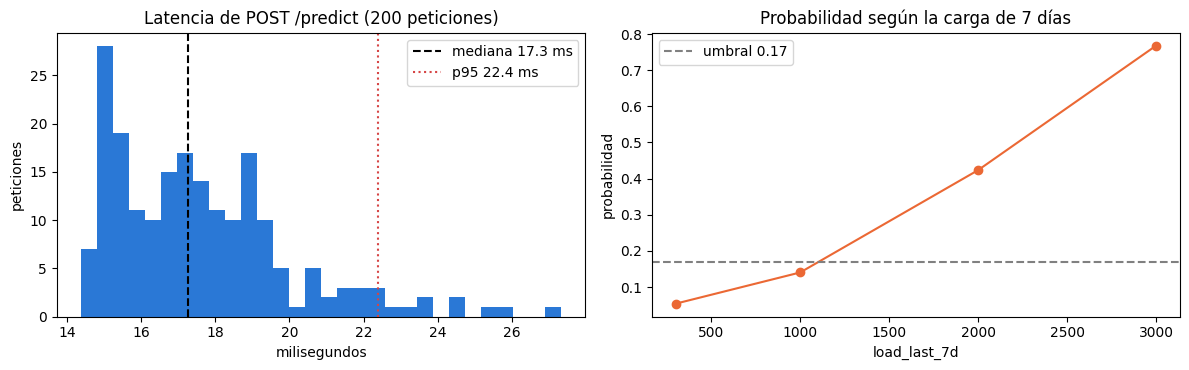

In [10]:
# Punto 8. Consistencia, sensibilidad a la carga y latencia.
# 1) Consistencia: 20 veces la misma entrada.
repetidas = {requests.post(f"{API_URL}/predict", json=ejemplos["moderado"]).json()["probabilidad"] for _ in range(20)}
print("C01 Consistencia: valores distintos en 20 peticiones =", len(repetidas), "->", "Pasa" if len(repetidas) == 1 else "No pasa")

# 2) Sensibilidad: el riesgo sube con la carga de 7 días.
cargas = [300, 1000, 2000, 3000]
riesgo_carga = [requests.post(f"{API_URL}/predict", json={**ejemplos["moderado"], "load_last_7d": c}).json()["probabilidad"]
                for c in cargas]
print("E04 Sensibilidad (carga 7 días -> probabilidad):", dict(zip(cargas, riesgo_carga)),
      "->", "Pasa" if riesgo_carga == sorted(riesgo_carga) else "No pasa")

# 3) Latencia: 200 peticiones.
tiempos = []
for _ in range(200):
    inicio = time.perf_counter()
    requests.post(f"{API_URL}/predict", json=ejemplos["moderado"])
    tiempos.append((time.perf_counter() - inicio) * 1000)          # milisegundos
mediana, p95 = np.median(tiempos), np.percentile(tiempos, 95)
print(f"L01 Latencia: mediana = {mediana:.1f} ms | percentil 95 = {p95:.1f} ms ->",
      "Pasa" if mediana < 100 and p95 < 300 else "No pasa")

# Gráfica de latencia para el documento de validación.
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
ejes[0].hist(tiempos, bins=30, color="#2a78d6")
ejes[0].axvline(mediana, color="black", ls="--", label=f"mediana {mediana:.1f} ms")
ejes[0].axvline(p95, color="#d64545", ls=":", label=f"p95 {p95:.1f} ms")
ejes[0].set(title="Latencia de POST /predict (200 peticiones)", xlabel="milisegundos", ylabel="peticiones")
ejes[0].legend()
ejes[1].plot(cargas, riesgo_carga, marker="o", color="#eb6834")
ejes[1].axhline(metadata["umbral"], color="gray", ls="--", label="umbral 0.17")
ejes[1].set(title="Probabilidad según la carga de 7 días", xlabel="load_last_7d", ylabel="probabilidad")
ejes[1].legend()
plt.tight_layout()
plt.savefig(EVIDENCIAS / "latencia_y_sensibilidad.png", dpi=150)
plt.show()

pd.DataFrame({"latencia_ms": tiempos}).to_csv(EVIDENCIAS / "latencia.csv", index=False)

## 9. Pruebas automatizadas con pytest

`tests/test_api.py` repite todos los casos anteriores como **pruebas automatizadas** (23 pruebas) contra el contenedor
en ejecución. Así cualquier persona puede validar la solución con un solo comando:

```
pytest tests/ -v
```

In [11]:
# Punto 9. Ejecutar la batería de pruebas automatizadas contra el contenedor.
pruebas = subprocess.run([sys.executable, "-m", "pytest", "tests/", "-v", "--no-header", "--color=no", "-p", "no:cacheprovider"],
                         cwd=RAIZ, capture_output=True, text=True)
salida = pruebas.stdout.strip().splitlines()
print("\n".join(line for line in salida if "::" in line or "passed" in line or "failed" in line))
(EVIDENCIAS / "resultado_pytest.txt").write_text(pruebas.stdout, encoding="utf-8")
print("Salida completa guardada en evidencias/resultado_pytest.txt")

tests/test_api.py::test_F01_health_check PASSED                          [  4%]
tests/test_api.py::test_F02_ficha_del_modelo PASSED                      [  8%]
tests/test_api.py::test_F03_prediccion_por_perfil[bajo-0-Bajo] PASSED    [ 13%]
tests/test_api.py::test_F03_prediccion_por_perfil[moderado-1-Moderado] PASSED [ 17%]
tests/test_api.py::test_F03_prediccion_por_perfil[alto-1-Alto] PASSED    [ 21%]
tests/test_api.py::test_F04_frontend_disponible PASSED                   [ 26%]
tests/test_api.py::test_F05_documentacion_swagger PASSED                 [ 30%]
tests/test_api.py::test_E01_datos_opcionales_vacios PASSED               [ 34%]
tests/test_api.py::test_E02_limites_minimos PASSED                       [ 39%]
tests/test_api.py::test_E03_limites_maximos PASSED                       [ 43%]
tests/test_api.py::test_E04_mas_carga_mas_riesgo PASSED                  [ 47%]
tests/test_api.py::test_E05_campos_extra_se_ignoran PASSED               [ 52%]
tests/test_api.py::test_V01_valores

## 10. Detener el contenedor

Antes de detenerlo, toma las capturas de `http://localhost:8000/app` (formulario con una predicción) y
`http://localhost:8000/docs` (Swagger) para el manual. Después ejecuta esta celda.

In [12]:
# Punto 10. Detener y borrar el contenedor (la imagen se conserva para volver a ejecutarla).
print(subprocess.run(["docker", "stop", "wodpredict"], capture_output=True, text=True).stdout.strip(), "detenido")
print(subprocess.run(["docker", "rm", "wodpredict"], capture_output=True, text=True).stdout.strip(), "borrado")

wodpredict detenido
wodpredict borrado


## 11. Conclusiones

- El modelo de las Actividades 5 y 6 quedó como un **artefacto versionado** (`model.pkl` + `metadata.json`)
  separado del entrenamiento, con las mismas métricas en prueba (recall 0.732, precisión 0.378, ROC-AUC 0.859).
- La **API REST** (FastAPI) define un contrato claro: 23 variables con tipo y rango, respuesta con probabilidad,
  alerta, nivel de riesgo y recomendación para el coach. Los datos inválidos se rechazan con 422 antes de llegar al modelo.
- El **contenedor Docker** construye sin errores, arranca como *healthy* y devuelve **exactamente las mismas
  probabilidades** que el modelo directo y que la API local: el entorno es portable.
- Las **pruebas** cubren el flujo normal, casos extremos (datos vacíos, mínimos y máximos), validación de entrada,
  consistencia y latencia, y se pueden repetir con `pytest`.
- **Despliegue en la nube:** la misma imagen se publicó en Azure Container Apps (Azure for Students, región México Central) como demo, activa solo durante la evaluación: https://wodpredict-api-mx.calmcliff-e9faa155.mexicocentral.azurecontainerapps.io/app/. Con `API_URL` apuntando a esa URL, pytest aprobó 22 de 23 pruebas con probabilidades idénticas a las locales; solo L01 (latencia ≈ 1.1 s) quedó fuera de la meta local, como se analiza en el documento de validación.